# Import

In [1]:
%reset -f
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append('../')

from sources.parameters import *
from sources.data import *
from sources.model import *
from sources.solver import *

2022-09-07 15:53:12.963620: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:936] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2022-09-07 15:53:12.980974: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudnn.so.8'; dlerror: libcudnn.so.8: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/run/user/1000/doc:/run/user/1000/doc
2022-09-07 15:53:12.980989: W tensorflow/core/common_runtime/gpu/gpu_device.cc:1850] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...
2022-09-07 15:53:12.981389: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is 

# Parameters

In [2]:
# Set boundary
tmin = 0.
tmax = 6.01
xmin = -3.
xmax = 3.
ymin = -3. 
ymax = 3.

# Lower bounds
lb = tf.constant([tmin, xmin, ymin], dtype=DTYPE)
# Upper bounds
ub = tf.constant([tmax, xmax, ymax], dtype=DTYPE)

# Load model

In [11]:
model = PhysicsInformedNN(lb, ub, output_dim=4, num_hidden_layers=8, num_neurons_per_layer=256, activation='tanh')
model.build(input_shape=(None,3))

model.load_weights(WEIGHT_PATH+' .h5')

# Model prediction

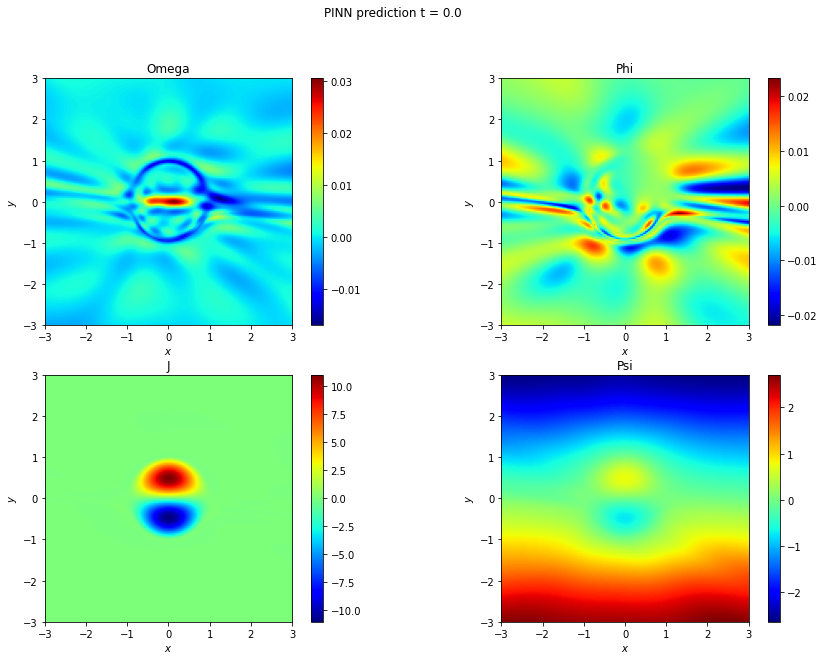

In [12]:
N = 150
t = 0.

# compute solution using PINN
xspace = np.linspace(-3,3,N)
yspace = np.linspace(-3,3,N)
tfinal = t * np.ones(N*N)

X, Y = np.meshgrid(xspace, yspace)
Xgrid = np.vstack([tfinal.flatten(), X.flatten(), Y.flatten()]).T
u = model(tf.cast(Xgrid,DTYPE))

omega, phi, J, psi = u[:,0:1], u[:,1:2], u[:,2:3], u[:,3:4]

# reshape for plotting
omega = omega.numpy().reshape(N,N)
phi = phi.numpy().reshape(N,N)
J = J.numpy().reshape(N,N)
psi = psi.numpy().reshape(N,N)

# affichage
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15,10))
axs = axs.flatten()

# plot omega
axs[0].set_xlabel('$x$')
axs[0].set_ylabel('$y$')
axs[0].set_aspect('equal')
img0 = axs[0].imshow(omega, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar0 = plt.colorbar(img0, ax=axs[0])
axs[0].set_title('Omega')

# plot phi
axs[1].set_xlabel('$x$')
axs[1].set_ylabel('$y$')
axs[1].set_aspect('equal')
img1 = axs[1].imshow(phi, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar1 = plt.colorbar(img1, ax=axs[1])
axs[1].set_title('Phi')

# plot J
axs[2].set_xlabel('$x$')
axs[2].set_ylabel('$y$')
axs[2].set_aspect('equal')
img2 = axs[2].imshow(J, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar2 = plt.colorbar(img2, ax=axs[2])
axs[2].set_title('J')

# plot psi
axs[3].set_xlabel('$x$')
axs[3].set_ylabel('$y$')
axs[3].set_aspect('equal')
img3 = axs[3].imshow(psi, cmap='jet', origin='lower', extent=[-3,3.,-3.,3.]);
cbar3 = plt.colorbar(img3, ax=axs[3])
axs[3].set_title('Psi')

#fig.tight_layout()
plt.suptitle('PINN prediction t = {}'.format(t));
plt.savefig(FIG_PATH+'MHD_PINN'+str(int(t*10)), bbox_inches='tight', dpi=fig.dpi, facecolor='w', edgecolor='w', transparent=False)

# plot value of interest

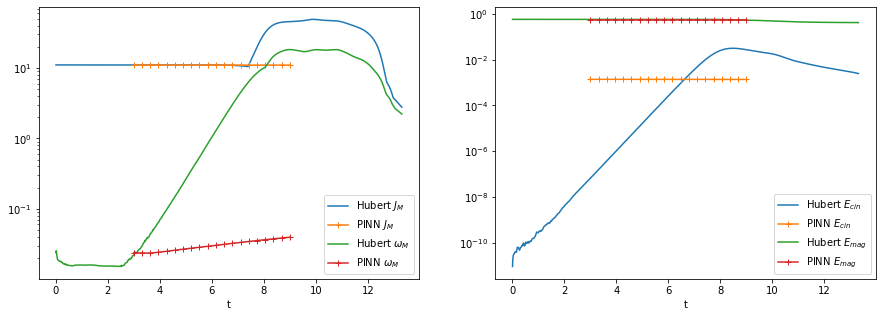

In [13]:
def plot_max_value(model):

    # spatial grid
    N = 120
    xspace = np.linspace(-3,3,N)
    yspace = np.linspace(-3,3,N)
    X, Y = np.meshgrid(xspace, yspace)
    
    omega_max = []
    J_max = []
    E_cin = []
    E_mag = []
    
    all_times = np.linspace(0.,6.,20)

    for t in all_times:

        tfinal = t * np.ones(N*N)
        Xgrid = np.vstack([tfinal.flatten(), X.flatten(), Y.flatten()]).T
        Xgrid = tf.cast(Xgrid,DTYPE)
        
        tfinal, x, y = Xgrid[:,0:1], Xgrid[:,1:2], Xgrid[:,2:3]
        with tf.GradientTape(persistent=True) as tape:
            tape.watch(x)
            tape.watch(y)
        
            u = model(tf.stack([tfinal[:,0], x[:,0], y[:,0]], axis=1))
            omega, phi, J, psi = u[:,0:1], u[:,1:2], u[:,2:3], u[:,3:4]
            
            phi_x = tape.gradient(phi, x)
            phi_y = tape.gradient(phi, y)
            
            psi_x = tape.gradient(psi, x)
            psi_y = tape.gradient(psi, y)
                    
        E_cin.append( tf.reduce_mean(phi_x*phi_x + phi_y*phi_y)/2 )
        E_mag.append( tf.reduce_mean(psi_x*psi_x + psi_y*psi_y)/2 )
        del tape
        omega_max.append((tf.reduce_max(omega)-tf.reduce_min(omega))/2)
        J_max.append((tf.reduce_max(J)-tf.reduce_min(J))/2)
        
    data = np.genfromtxt (DATA_PATH+'histo.dat', delimiter=" ", skip_header=1)
        
    fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15,5))
    axs = axs.flatten()
    
    all_times = [x+3. for x in all_times]
    axs[0].semilogy(data[:,0], data[:,1], '-', label=r'Hubert $J_M$')
    axs[0].semilogy(all_times, J_max, '+-', label=r'PINN $J_M$')
    axs[0].semilogy(data[:,0], data[:,3], '-', label=r'Hubert $\omega_M$')
    axs[0].semilogy(all_times, omega_max, '+-', label=r'PINN $\omega_M$')
    axs[0].set_xlabel('t')
    axs[0].set_ylabel('')
    axs[0].legend()
    
    axs[1].semilogy(data[:,0], data[:,4], '-', label=r'Hubert $E_{cin}$')
    axs[1].semilogy(all_times, E_cin, '+-', label=r'PINN $E_{cin}$')
    axs[1].semilogy(data[:,0], data[:,6], '-', label=r'Hubert $E_{mag}$')
    axs[1].semilogy(all_times, E_mag, '+-', label=r'PINN $E_{mag}$')
    axs[1].set_xlabel('t')
    axs[1].set_ylabel('')
    axs[1].legend()
    
    #plt.savefig(FIG_PATH+'wow', bbox_inches='tight', dpi=fig.dpi, facecolor='w', edgecolor='w', transparent=False)
    
plot_max_value(model)